In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

print("All libraries are installed successfully!")

All libraries are installed successfully!


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [7]:
COLUMNS = [
   "age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
   "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
   "hours-per-week", "native-country", "income"
]

In [37]:
adult_data = pd.read_csv(
   "adultdata.csv",        # your file name
   header=None,            # because original file has no header row
   names=COLUMNS,          # assign the 15 column names
   sep=",",                # comma-separated
   skipinitialspace=True,  # remove spaces after commas
   na_values=["?"],  # treat '?' as missing
   engine="python",
   on_bad_lines="skip"     # skip malformed rows if any
)

print(adult_data.shape)      # should show rows × 15 columns
print(adult_data)     # first 5 rows with column names
adult_data.describe()
adult_data.head()
adult_data.shape

(32561, 15)
       age         workclass  fnlwgt   education  education-num  \
0       39         State-gov   77516   Bachelors             13   
1       50  Self-emp-not-inc   83311   Bachelors             13   
2       38           Private  215646     HS-grad              9   
3       53           Private  234721        11th              7   
4       28           Private  338409   Bachelors             13   
...    ...               ...     ...         ...            ...   
32556   27           Private  257302  Assoc-acdm             12   
32557   40           Private  154374     HS-grad              9   
32558   58           Private  151910     HS-grad              9   
32559   22           Private  201490     HS-grad              9   
32560   52      Self-emp-inc  287927     HS-grad              9   

           marital-status         occupation   relationship   race     sex  \
0           Never-married       Adm-clerical  Not-in-family  White    Male   
1      Married-civ-spouse  

(32561, 15)

In [10]:
for col in adult_data.columns:
   print(col)
   print(adult_data[col].value_counts(dropna=False).head(10))
   print('-'*50)

age
36    898
31    888
34    886
23    877
35    876
33    875
28    867
30    861
37    858
25    841
Name: age, dtype: int64
--------------------------------------------------
workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
NaN                  1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: workclass, dtype: int64
--------------------------------------------------
fnlwgt
164190    13
203488    13
123011    13
148995    12
121124    12
113364    12
126675    12
111483    11
120277    11
123983    11
Name: fnlwgt, dtype: int64
--------------------------------------------------
education
HS-grad         10501
Some-college     7291
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
Name: education, dtype: int64
---------------------

In [11]:
for col in adult_data.columns:
   mod_val= adult_data[col].mode()
   adult_data[col].fillna(mod_val[0],inplace=True)

In [12]:
adult_data.isna().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

In [13]:
adult_data

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [14]:
obj_col=adult_data.select_dtypes(include='object').columns
for col in obj_col:
   adult_data[col]=adult_data[col].astype(str).str.strip().str.lower()
adult_data

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,state-gov,77516,bachelors,13,never-married,adm-clerical,not-in-family,white,male,2174,0,40,united-states,<=50k
1,50,self-emp-not-inc,83311,bachelors,13,married-civ-spouse,exec-managerial,husband,white,male,0,0,13,united-states,<=50k
2,38,private,215646,hs-grad,9,divorced,handlers-cleaners,not-in-family,white,male,0,0,40,united-states,<=50k
3,53,private,234721,11th,7,married-civ-spouse,handlers-cleaners,husband,black,male,0,0,40,united-states,<=50k
4,28,private,338409,bachelors,13,married-civ-spouse,prof-specialty,wife,black,female,0,0,40,cuba,<=50k
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,private,257302,assoc-acdm,12,married-civ-spouse,tech-support,wife,white,female,0,0,38,united-states,<=50k
32557,40,private,154374,hs-grad,9,married-civ-spouse,machine-op-inspct,husband,white,male,0,0,40,united-states,>50k
32558,58,private,151910,hs-grad,9,widowed,adm-clerical,unmarried,white,female,0,0,40,united-states,<=50k
32559,22,private,201490,hs-grad,9,never-married,adm-clerical,own-child,white,male,0,0,20,united-states,<=50k


In [15]:
adult_data.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [16]:
numerical_col_data= adult_data.select_dtypes(include=['int64','float64']).columns

for col in numerical_col_data:
   adult_data[col]=pd.to_numeric(adult_data[col],errors='coerce')
adult_data.head(10)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,state-gov,77516,bachelors,13,never-married,adm-clerical,not-in-family,white,male,2174,0,40,united-states,<=50k
1,50,self-emp-not-inc,83311,bachelors,13,married-civ-spouse,exec-managerial,husband,white,male,0,0,13,united-states,<=50k
2,38,private,215646,hs-grad,9,divorced,handlers-cleaners,not-in-family,white,male,0,0,40,united-states,<=50k
3,53,private,234721,11th,7,married-civ-spouse,handlers-cleaners,husband,black,male,0,0,40,united-states,<=50k
4,28,private,338409,bachelors,13,married-civ-spouse,prof-specialty,wife,black,female,0,0,40,cuba,<=50k
5,37,private,284582,masters,14,married-civ-spouse,exec-managerial,wife,white,female,0,0,40,united-states,<=50k
6,49,private,160187,9th,5,married-spouse-absent,other-service,not-in-family,black,female,0,0,16,jamaica,<=50k
7,52,self-emp-not-inc,209642,hs-grad,9,married-civ-spouse,exec-managerial,husband,white,male,0,0,45,united-states,>50k
8,31,private,45781,masters,14,never-married,prof-specialty,not-in-family,white,female,14084,0,50,united-states,>50k
9,42,private,159449,bachelors,13,married-civ-spouse,exec-managerial,husband,white,male,5178,0,40,united-states,>50k


In [17]:
adult_data.isna().sum()


age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

In [18]:
adult_data.duplicated().sum()

24

In [19]:
adult_data.drop_duplicates(inplace=True)

In [20]:
adult_data.duplicated().sum()

0

In [21]:
adult_data

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,state-gov,77516,bachelors,13,never-married,adm-clerical,not-in-family,white,male,2174,0,40,united-states,<=50k
1,50,self-emp-not-inc,83311,bachelors,13,married-civ-spouse,exec-managerial,husband,white,male,0,0,13,united-states,<=50k
2,38,private,215646,hs-grad,9,divorced,handlers-cleaners,not-in-family,white,male,0,0,40,united-states,<=50k
3,53,private,234721,11th,7,married-civ-spouse,handlers-cleaners,husband,black,male,0,0,40,united-states,<=50k
4,28,private,338409,bachelors,13,married-civ-spouse,prof-specialty,wife,black,female,0,0,40,cuba,<=50k
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,private,257302,assoc-acdm,12,married-civ-spouse,tech-support,wife,white,female,0,0,38,united-states,<=50k
32557,40,private,154374,hs-grad,9,married-civ-spouse,machine-op-inspct,husband,white,male,0,0,40,united-states,>50k
32558,58,private,151910,hs-grad,9,widowed,adm-clerical,unmarried,white,female,0,0,40,united-states,<=50k
32559,22,private,201490,hs-grad,9,never-married,adm-clerical,own-child,white,male,0,0,20,united-states,<=50k


In [22]:
adult_data.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32537.000000,3.253700e+04,32537.000000,32537.000000,32537.000000,32537.000000
mean,38.585549,1.897808e+05,10.081815,1078.443741,87.368227,40.440329
std,13.637984,1.055565e+05,2.571633,7387.957424,403.101833,12.346889
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.369930e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [23]:
numerical_col_data=adult_data.select_dtypes(include=['int64','float64']).columns
numerical_col_data

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

In [24]:
def remove_outliers(df,col):
   Q1= df[col].quantile(0.25)
   Q3= df[col].quantile(0.75)
   IQR= Q3-Q1
   lower = Q1- 1.5*IQR
   upper= Q3+ 1.5*IQR
   return df[(df[col]>=lower) & (df[col]<=upper)]

for col in numerical_col_data:
   adult_data= remove_outliers(adult_data,col)
adult_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
2,38,private,215646,hs-grad,9,divorced,handlers-cleaners,not-in-family,white,male,0,0,40,united-states,<=50k
3,53,private,234721,11th,7,married-civ-spouse,handlers-cleaners,husband,black,male,0,0,40,united-states,<=50k
4,28,private,338409,bachelors,13,married-civ-spouse,prof-specialty,wife,black,female,0,0,40,cuba,<=50k
5,37,private,284582,masters,14,married-civ-spouse,exec-managerial,wife,white,female,0,0,40,united-states,<=50k
7,52,self-emp-not-inc,209642,hs-grad,9,married-civ-spouse,exec-managerial,husband,white,male,0,0,45,united-states,>50k


In [25]:
adult_data

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
2,38,private,215646,hs-grad,9,divorced,handlers-cleaners,not-in-family,white,male,0,0,40,united-states,<=50k
3,53,private,234721,11th,7,married-civ-spouse,handlers-cleaners,husband,black,male,0,0,40,united-states,<=50k
4,28,private,338409,bachelors,13,married-civ-spouse,prof-specialty,wife,black,female,0,0,40,cuba,<=50k
5,37,private,284582,masters,14,married-civ-spouse,exec-managerial,wife,white,female,0,0,40,united-states,<=50k
7,52,self-emp-not-inc,209642,hs-grad,9,married-civ-spouse,exec-managerial,husband,white,male,0,0,45,united-states,>50k
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32554,53,private,321865,masters,14,married-civ-spouse,exec-managerial,husband,white,male,0,0,40,united-states,>50k
32555,22,private,310152,some-college,10,never-married,protective-serv,not-in-family,white,male,0,0,40,united-states,<=50k
32556,27,private,257302,assoc-acdm,12,married-civ-spouse,tech-support,wife,white,female,0,0,38,united-states,<=50k
32557,40,private,154374,hs-grad,9,married-civ-spouse,machine-op-inspct,husband,white,male,0,0,40,united-states,>50k


In [ ]:
print(adult_data.columns.tolist())

In [ ]:
plt.figure(figsize=(5,5))
sns.boxplot(x=adult_data['income'],y=adult_data['hours-per-week'])
plt.title('Working hours vs Earning potential')
plt.show()

In [26]:
adult_data.groupby('income')['hours-per-week'].mean()


adult_data['income']=adult_data['income'].str.strip().str.lower()
adult_data['income_binary']=adult_data['income'].map({'<=50k':0,'>50k':1})
adult_data.head(10)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,income_binary
2,38,private,215646,hs-grad,9,divorced,handlers-cleaners,not-in-family,white,male,0,0,40,united-states,<=50k,0
3,53,private,234721,11th,7,married-civ-spouse,handlers-cleaners,husband,black,male,0,0,40,united-states,<=50k,0
4,28,private,338409,bachelors,13,married-civ-spouse,prof-specialty,wife,black,female,0,0,40,cuba,<=50k,0
5,37,private,284582,masters,14,married-civ-spouse,exec-managerial,wife,white,female,0,0,40,united-states,<=50k,0
7,52,self-emp-not-inc,209642,hs-grad,9,married-civ-spouse,exec-managerial,husband,white,male,0,0,45,united-states,>50k,1
11,30,state-gov,141297,bachelors,13,married-civ-spouse,prof-specialty,husband,asian-pac-islander,male,0,0,40,india,>50k,1
13,32,private,205019,assoc-acdm,12,never-married,sales,not-in-family,black,male,0,0,50,united-states,<=50k,0
14,40,private,121772,assoc-voc,11,married-civ-spouse,craft-repair,husband,asian-pac-islander,male,0,0,40,united-states,>50k,1
16,25,self-emp-not-inc,176756,hs-grad,9,never-married,farming-fishing,own-child,white,male,0,0,35,united-states,<=50k,0
17,32,private,186824,hs-grad,9,never-married,machine-op-inspct,unmarried,white,male,0,0,40,united-states,<=50k,0


In [27]:
from scipy.stats import pointbiserialr

r,p= pointbiserialr(adult_data['age'],adult_data['income_binary'])
print('Correlation: ',r)
print('P-value: ', p)


Correlation:  0.24564866936519553
P-value:  5.350075869111996e-259


In [28]:
from scipy.stats import pointbiserialr

features = ['age', 'education-num', 'hours-per-week']
# include fnlwgt or fnlweight depending on your column name
features.append('fnlwgt' if 'fnlwgt' in adult_data.columns else 'fnlweight')

for col in features:
   valid = adult_data[[col, 'income_binary']].dropna()
   r, p = pointbiserialr(valid[col], valid['income_binary'])
   print(f'{col}: Correlation = {r:.4f}, P-value = {p:.4e}')

age: Correlation = 0.2456, P-value = 5.3501e-259
education-num: Correlation = 0.2951, P-value = 0.0000e+00
hours-per-week: Correlation = 0.1728, P-value = 3.7729e-127
fnlwgt: Correlation = 0.0004, P-value = 9.5896e-01


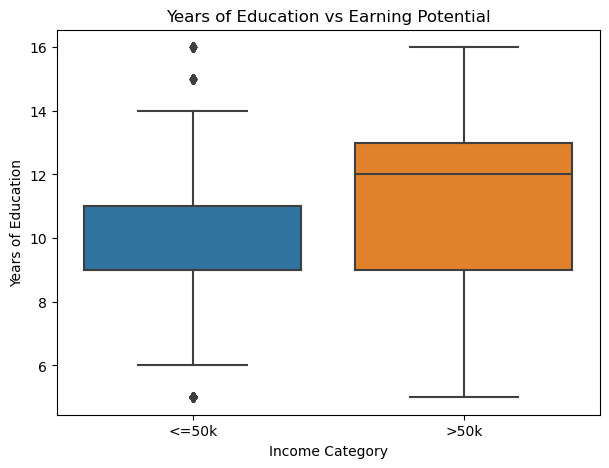

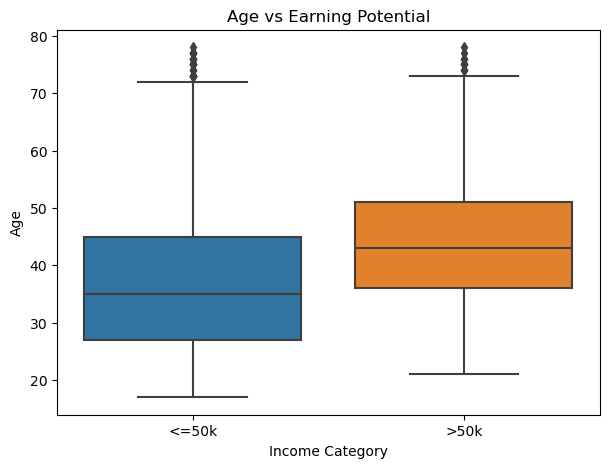

In [29]:
plt.figure(figsize=(7,5))
sns.boxplot(x='income', y='education-num', data=adult_data)
plt.title('Years of Education vs Earning Potential')
plt.xlabel('Income Category')
plt.ylabel('Years of Education')
plt.show()


plt.figure(figsize=(7,5))
sns.boxplot(x='income', y='age', data=adult_data)
plt.title('Age vs Earning Potential')
plt.xlabel('Income Category')
plt.ylabel('Age')
plt.show()


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# If your data uses 'native-country', swap the name in your list
categorical_cols = ['workclass','education','marital-status','occupation',
                   'relationship','race','sex','country']
if 'country' not in adult_data.columns and 'native-country' in adult_data.columns:
   categorical_cols = [c if c != 'country' else 'native-country' for c in categorical_cols]

X = adult_data.drop('income', axis=1)
y = adult_data['income']

# Keep only columns that exist
categorical_cols = [c for c in categorical_cols if c in X.columns]
numerical_col_data = [c for c in numerical_col_data if c in X.columns]

# Use sparse_output=False (works on sklearn >= 1.2)
preprocessor = ColumnTransformer(
   transformers=[
       ('num', StandardScaler(), numerical_col_data),
       ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
   ],
   remainder='drop'
)

X_processed = preprocessor.fit_transform(X)
print("\nShape after feature engineering:", X_processed.shape)



Shape after feature engineering: (18991, 100)


In [31]:
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, confusion_matrix
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1) Target & features (avoid leakage)
if 'income_binary' not in adult_data.columns:
   raise ValueError("income_binary not found. Please create it before modeling.")

X = adult_data.drop(columns=['income', 'income_binary'], errors='ignore')
y = adult_data['income_binary'].astype(int)

# 2) Stratified split
X_train, X_test, y_train, y_test = train_test_split(
   X, y, test_size=0.20, random_state=42, stratify=y
)

# 3) Column setup
categorical_cols = ['workclass', 'education', 'marital-status', 'occupation',
                   'relationship', 'race', 'sex', 'country']
if 'country' not in X_train.columns and 'native-country' in X_train.columns:
   categorical_cols = [c if c != 'country' else 'native-country' for c in categorical_cols]
categorical_cols = [c for c in categorical_cols if c in X_train.columns]
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 4) Preprocessor (fit only on train)
try:
   ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
   ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor = ColumnTransformer(
   transformers=[
       ('num', StandardScaler(), numerical_cols),
       ('cat', ohe, categorical_cols)
   ],
   remainder='drop'
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc  = preprocessor.transform(X_test)
print(f"Processed shapes — Train: {X_train_proc.shape}, Test: {X_test_proc.shape}")

Processed shapes — Train: (15192, 100), Test: (3799, 100)


hi
